In [1]:

import numpy as np
import pandas as pd
from pathlib import Path

# Load processed Titanic datasets
data_path = Path("/kaggle/input")

train_path = next(data_path.rglob("titanic_train_processed.csv"))
test_path = next(data_path.rglob("titanic_test_processed.csv"))

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

# Separate features and target
X_train = train.drop(columns="Survived").values
y_train = train["Survived"].values

X_test = test.drop(columns="Survived").values
y_test = test["Survived"].values

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)



Training: (712, 10) (712,)
Testing: (179, 10) (179,)


In [2]:

# Logistic Regression using Gradient Descent + Momentum

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Add bias column
X = np.c_[np.ones(len(X_train)), X_train]

# Initialize parameters
weights = np.zeros(X.shape[1])
velocity = np.zeros_like(weights)

lr = 0.05
momentum = 0.9
epochs = 2000
loss_history = []

for epoch in range(epochs):
    predictions = sigmoid(X @ weights)

    # Binary Cross-Entropy Loss
    p = np.clip(predictions, 1e-10, 1 - 1e-10)
    loss = -np.mean(y_train * np.log(p) +
                    (1 - y_train) * np.log(1 - p))
    loss_history.append(loss)

    # Gradient Descent with Momentum
    gradient = X.T @ (predictions - y_train) / len(y_train)
    velocity = momentum * velocity + gradient
    weights -= lr * velocity

print("Training completed!")
print("Final Training Loss:", loss_history[-1])
print("Learned Weights:", weights)

Training completed!
Final Training Loss: 0.43610999499705305
Learned Weights: [-0.66227829 -0.95199863 -0.5186134  -0.26881351 -0.07058704  0.0917472
  0.64377688 -0.64377688  0.05080353  0.11945296 -0.11685861]


Accuracy : 0.8100558659217877
Precision: 0.7966101694915254
Recall   : 0.6811594202898551
F1 Score : 0.734375
Test Loss: 0.46361711901561264


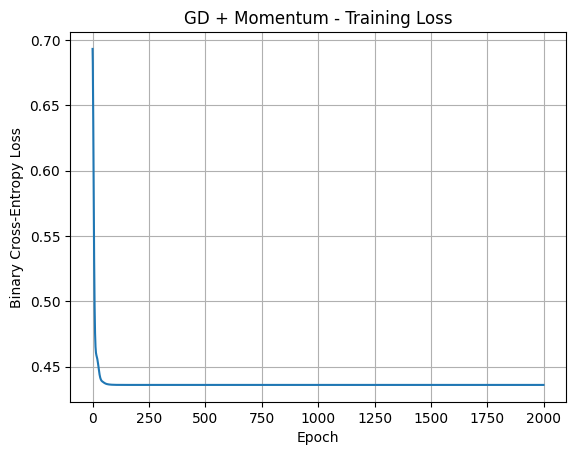

In [3]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Predict on test data
X_test_bias = np.c_[np.ones(len(X_test)), X_test]
probabilities = sigmoid(X_test_bias @ weights)
y_pred = (probabilities >= 0.5).astype(int)

# Calculate evaluation metrics
p = np.clip(probabilities, 1e-10, 1 - 1e-10)
test_loss = -np.mean(y_test * np.log(p) +
                     (1 - y_test) * np.log(1 - p))

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))
print("Test Loss:", test_loss)

# Plot training loss
plt.plot(loss_history)
plt.title("GD + Momentum - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()